# Mouse and human pseudotime trajectories (Fig. S20, S27)

November fib/dec pseudotime objects in (from `pseudotime/`), Fig. S20 (mouse) and S27 (human) out: the diffusion map
colored by timepoint (A), subtype or cell type (B) and pseudotime with the root starred (C), and pseudotime by
timepoint (D). One composite SVG per figure and one SVG per panel, written to `OUT`.

Drawing code is that of the previous version of these figures (2 Nov). Differences:

- November labels (mouse `1.5dpi_early` ... `4.5dpi_menstrual`; human `eFib`, `dec`)
- apoptotic nuclei (mouse `decAp`; human `decAp1`, `decAp2`) have no pseudotime and are not drawn
- more room above the mouse trajectory, which arcs up under the legends
- mouse panel B titled "Subtype"; panel D files named by timepoint

Font: Helvetica Neue if `FONT_FILE` points to it; otherwise DejaVu Sans (`DRAFT_FONT = True`).

In [1]:
# Parameters
MOUSE = "/n/lab_storage/eddy_lab/Lab/mckinley/data/20261110_mouse_only_eFib_dec_final_nick_pdt.h5ad"
HUMAN = "/n/lab_storage/eddy_lab/Lab/mckinley/data/20261107_Human_fibdec_final_nick_pdt.h5ad"
OUT = "S20_S27_pseudotime_trajectories_files"  # a new folder; a relative path is next to the notebook

FONT_FILE = ""  # a Helvetica Neue font file, if there is one
DRAFT_FONT = True  # True: matplotlib's DejaVu Sans when Helvetica Neue is missing (the cluster); False: stop

## Setup

In [2]:
import datetime
import hashlib
import json
from io import BytesIO
from pathlib import Path

import matplotlib

# Figures go to files and previews are shown as PNGs, so the notebook backend's own rc settings
# never reach the saved SVGs.
matplotlib.use("Agg")

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from IPython.display import Image, display

FONT = "Helvetica Neue"

DPI = 600  # resolution of the rasterized scatter layers embedded in the SVGs
PREVIEW_DPI = 90  # notebook previews only
PANEL_PAD_IN = 0.02  # margin around each standalone panel, inches

# Column names of the per-nucleus plotting table
PT = "pseudotime"
DC1, DC2 = "dc1", "dc2"

# Apoptotic decidual nuclei are left out of the pseudotime by design (mouse decAp; human decAp1, decAp2);
# every other nucleus must have a value.
NO_PSEUDOTIME_SUBTYPES = {"decAp", "decAp1", "decAp2"}

# Output files
S20_FILES = {
    "figure": "S20_mouse_pseudotime_composite.svg",
    "a": "S20A_mouse_diffusion_map_by_timepoint.svg",
    "b": "S20B_mouse_diffusion_map_by_subtype.svg",
    "c": "S20C_mouse_diffusion_map_by_pseudotime.svg",
    "d": "S20D_mouse_pseudotime_by_timepoint.svg",
}
S27_FILES = {
    "figure": "S27_human_pseudotime_composite.svg",
    "a": "S27A_human_diffusion_map_by_cycle_phase.svg",
    "b": "S27B_human_diffusion_map_by_celltype.svg",
    "c": "S27C_human_diffusion_map_by_pseudotime.svg",
    "d": "S27D_human_pseudotime_by_timepoint.svg",
}


# Every piece of text a reader sees. Keys are the values stored in the November objects; the *_tick variants
# are the line-broken forms used under violins.

LABELS = {
    "mouse_timepoint": {
        "uninduced": "uninduced",
        "1.5dpi_early": "1.5 dpi early",
        "1.5dpi_late": "1.5 dpi late",
        "2.5dpi": "2.5 dpi",
        "3.5dpi": "3.5 dpi",
        "4.5dpi_menstrual": "4.5 dpi menstrual",
    },
    "mouse_timepoint_tick": {
        "uninduced": "uninduced",
        "1.5dpi_early": "1.5 dpi\nearly",
        "1.5dpi_late": "1.5 dpi\nlate",
        "2.5dpi": "2.5 dpi",
        "3.5dpi": "3.5 dpi",
        "4.5dpi_menstrual": "4.5 dpi\nmenstrual",
    },
    "mouse_subtype": {
        "eFib1": "eFib1 outer",
        "eFib2": "eFib2 middle",
        "eFib2i": "eFib2i ind. middle",
        "eFib3": "eFib3 subluminal",
        "eFibP": "eFibP prolif.",
        "dec1": "dec1 boundary",
        "dec2": "dec2 prolif.",
        "dec3": "dec3 mature",
    },
    "human_timepoint": {
        "secretory": "secretory",
        "menstrual": "menstrual",
    },
    "human_cell_type": {
        "eFib": "Endometrial fibroblasts",
        "dec": "Decidual cells",
    },
    "mouse_title": "Mouse stromal lineage (apoptotic decidual cells excluded)",
    "human_title": "Human stromal lineage (apoptotic decidual cells excluded)",
    "title_timepoint": "Timepoint",
    "title_cell_type": "Cell type",
    "title_subtype": "Subtype",
    "title_pseudotime": "Pseudotime",
    "title_violin_timepoint": "Pseudotime by timepoint (fill color = median)",
    "dc1": "DC1",
    "dc2": "DC2",
    "pseudotime_rank": "pseudotime (rank)",
    "root": "root",
    "n_cells": "n = {thousands:.1f}k",  # under each violin
    "panel_letters": {"a": "A", "b": "B", "c": "C", "d": "D"},
}


# Sizes and colors are those of the October figures.

FONT_SIZE_BASE = 8  # titles, axis labels
FONT_SIZE_TICK = 6  # tick labels, legends, small annotations

# White-background supplement style shared by all three figures
SUPP_RC = {
    "font.size": FONT_SIZE_BASE,
    "axes.labelsize": FONT_SIZE_BASE,
    "axes.titlesize": FONT_SIZE_BASE,
    "xtick.labelsize": FONT_SIZE_TICK,
    "ytick.labelsize": FONT_SIZE_TICK,
    "legend.fontsize": FONT_SIZE_TICK,
    "axes.linewidth": 0.6,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
}

# Pseudotime is always plasma on 0-1; violins are filled with the plasma color of their median.
PT_CMAP = "plasma"

# Mouse timepoints: gray baseline, then light green to dark navy as the cycle advances.
MOUSE_TIMEPOINT_COLORS = {
    "uninduced": "#9AA5B1",
    "1.5dpi_early": "#A8DDB5",
    "1.5dpi_late": "#4EB3A3",
    "2.5dpi": "#2B8CBE",
    "3.5dpi": "#4A58B0",
    "4.5dpi_menstrual": "#1B1A55",
}

# Mouse subtypes: fibroblasts in pinks (light = outer, dark = proliferative), decidual cells in blues and
# purple.
MOUSE_SUBTYPE_COLORS = {
    "eFib1": "#F3BFD1",
    "eFib2": "#E58FAF",
    "eFib2i": "#C8668A",
    "eFib3": "#9C3E65",
    "eFibP": "#5E1A3B",
    "dec1": "#3FA7C9",
    "dec2": "#2E5FB8",
    "dec3": "#7A5CC0",
}

HUMAN_TIMEPOINT_COLORS = {"secretory": "#E9A23B", "menstrual": "#B5446E"}
HUMAN_CELL_TYPE_COLORS = {"eFib": "#C8668A", "dec": "#4F86D6"}

ROOT_STAR_COLOR = "#00B3B3"  # teal, stands out against every plasma color

# Supplement layout: two rows of two panels on a full-width page.
FIG_SIZE_IN = (7.2, 6.2)
GRID = dict(nrows=2, ncols=2, hspace=0.42, wspace=0.22, left=0.07, right=0.98, top=0.9, bottom=0.1)
SLOTS = {"a": (0, 0), "b": (0, 1), "c": (1, 0), "d": (1, 1)}
LETTER_DX = {"a": -0.06, "b": -0.06, "c": -0.06, "d": -0.1}  # axes fraction

## Inputs and checks

Reads `obs`, `obsm['X_diffmap']` and `uns['pseudotime']`. Stops if the root is not the nucleus with the lowest
pseudotime, or if a nucleus other than an apoptotic one has no pseudotime.

In [3]:
def sha256_of(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 24), b""):
            digest.update(block)
    return digest.hexdigest()


def cells_from_object(path: Path) -> pd.DataFrame:
    """Per-nucleus plotting table of one final object: obs, one obsm entry and uns['pseudotime']."""
    adata = ad.read_h5ad(path, backed="r")
    diffmap = np.asarray(adata.obsm["X_diffmap"])
    cells = pd.DataFrame(
        {
            "timepoint": adata.obs["timepoint"].astype(str).to_numpy(),
            "cell_type": adata.obs["cell_type"].astype(str).to_numpy(),
            "cell_subtype": adata.obs["cell_subtype"].astype(str).to_numpy(),
            PT: adata.obs["pseudotime"].to_numpy(dtype="float64"),
            DC1: diffmap[:, 1],
            DC2: diffmap[:, 2],
        },
        index=pd.Index(adata.obs_names, name="nucleus"),
    )
    cells["root"] = cells.index == str(adata.uns["pseudotime"]["root"])
    adata.file.close()
    return cells


def read_cells(path: Path) -> tuple[pd.DataFrame, dict]:
    """The plotting table of an object, and a record of its source."""
    return cells_from_object(path), {"object": str(path), "object_sha256": sha256_of(path)}


def check_cells(cells: pd.DataFrame, species: str) -> str:
    """Stop on anything the figures would draw wrongly; return the root nucleus."""
    roots = cells.index[cells["root"]]
    if len(roots) != 1:
        raise ValueError(f"{species}: expected one root nucleus, found {len(roots)}")
    root = roots[0]
    if cells.loc[root, PT] != cells[PT].min():
        raise ValueError(f"{species}: the root {root} does not have the lowest pseudotime")

    no_value = cells[PT].isna()
    if not (no_value == cells[DC1].isna()).all() or not (no_value == cells[DC2].isna()).all():
        raise ValueError(f"{species}: pseudotime and diffusion-map coverage differ")
    unexpected = set(cells.loc[no_value, "cell_subtype"]) - NO_PSEUDOTIME_SUBTYPES
    if unexpected:
        raise ValueError(f"{species}: nuclei without pseudotime outside {NO_PSEUDOTIME_SUBTYPES}: {unexpected}")
    return root

## Panel drawing

In [4]:
# Panels A-C of both supplements are diffusion-map scatters (DC1 vs DC2, no ticks: the axes have no units).
# Panel D is a violin per timepoint. Each function draws one panel into an axes and nothing else.

def relative_luminance(rgba) -> float:
    """WCAG relative luminance; decides white or black median ticks on a violin fill."""
    r, g, b = [x / 12.92 if x <= 0.03928 else ((x + 0.055) / 1.055) ** 2.4 for x in rgba[:3]]
    return 0.2126 * r + 0.7152 * g + 0.0722 * b


def save_svg(fig, path: Path, crop_to_content: bool = False) -> None:
    """Write an SVG with no date stamp; panels are cropped to their own artists."""
    options = {"dpi": DPI, "metadata": {"Date": None}}
    if crop_to_content:
        options |= {"bbox_inches": "tight", "pad_inches": PANEL_PAD_IN}
    fig.savefig(path, **options)
    print(f"wrote {path.name}")


def add_panel_letter(ax, key: str) -> None:
    ax.text(
        LETTER_DX[key],
        1.06,
        LABELS["panel_letters"][key],
        transform=ax.transAxes,
        fontsize=FONT_SIZE_BASE + 2,
        fontweight="bold",
        va="bottom",
        ha="right",
    )


def n_label(n_cells: int) -> str:
    return LABELS["n_cells"].format(thousands=n_cells / 1000)


def style_embedding_axes(ax, title: str) -> None:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel(LABELS["dc1"], labelpad=2)
    ax.set_ylabel(LABELS["dc2"], labelpad=2)
    ax.set_title(title, loc="left", pad=3)
    ax.margins(0.03)


def color_key_legend(ax, keys, colors, labels, **placement) -> None:
    handles = [
        Line2D([], [], ls="", marker="o", ms=4.5, mfc=colors[k], mec="none", label=labels[k])
        for k in keys
    ]
    ax.legend(
        handles=handles,
        frameon=False,
        handletextpad=0.1,
        columnspacing=0.8,
        borderaxespad=0.3,
        labelspacing=0.3,
        fontsize=FONT_SIZE_TICK,
        **placement,
    )


def mark_root(ax, xy, text_offset_pt, ha: str, va: str) -> None:
    """Star on the DPT root nucleus (pseudotime 0)."""
    ax.scatter(
        [xy[0]],
        [xy[1]],
        marker="*",
        s=80,
        c=ROOT_STAR_COLOR,
        edgecolors="black",
        linewidths=0.5,
        zorder=5,
    )
    ax.annotate(
        LABELS["root"],
        xy=xy,
        xytext=text_offset_pt,
        textcoords="offset points",
        fontsize=FONT_SIZE_TICK,
        ha=ha,
        va=va,
    )


def inset_pseudotime_colorbar(fig, ax, rect) -> None:
    cax = ax.inset_axes(rect)
    colorbar = fig.colorbar(
        ScalarMappable(Normalize(0, 1), PT_CMAP),
        cax=cax,
        ticks=[0, 0.5, 1],
        orientation="horizontal",
    )
    colorbar.outline.set_visible(False)
    colorbar.ax.tick_params(length=2, labelsize=FONT_SIZE_TICK, pad=1)
    cax.set_title(LABELS["pseudotime_rank"], fontsize=FONT_SIZE_TICK, pad=2)


def median_filled_violins(ax, values_per_group, width: float) -> None:
    """Violins (Gaussian KDE, bw 0.15) filled with the plasma color of the group median.

    The median tick is white on dark fills and black on light ones so it stays visible.
    """
    medians = [float(np.median(v)) for v in values_per_group]
    positions = np.arange(len(values_per_group))
    cmap = plt.get_cmap(PT_CMAP)

    violins = ax.violinplot(
        values_per_group,
        positions=positions,
        widths=width,
        showextrema=False,
        bw_method=0.15,
    )
    for body, median in zip(violins["bodies"], medians):
        body.set_facecolor(cmap(median))
        body.set_edgecolor("black")
        body.set_linewidth(0.4)
        body.set_alpha(1.0)

    tick_colors = ["white" if relative_luminance(cmap(m)) < 0.18 else "black" for m in medians]
    ax.scatter(positions, medians, marker="_", s=110, c=tick_colors, lw=1.2, zorder=4)

    ax.set_xticks(positions)
    ax.set_xlim(-0.6, len(values_per_group) - 0.4)
    ax.set_ylim(-0.03, 1.03)
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel(LABELS["pseudotime_rank"])


def violins_by_timepoint(ax, cells, timepoint_order, tick_labels) -> None:
    """Panel D of both supplements: one violin per timepoint, every nucleus with a pseudotime included."""
    values = [cells.loc[cells["timepoint"] == t, PT].to_numpy() for t in timepoint_order]

    # Narrower violins when there are only a few groups (human: two timepoints)
    width = 0.8 if len(timepoint_order) > 3 else 0.55
    median_filled_violins(ax, values, width)

    ax.set_xticklabels(
        [f"{tick_labels[t]}\n{n_label(len(v))}" for t, v in zip(timepoint_order, values)],
        fontsize=FONT_SIZE_TICK,
    )
    ax.set_title(LABELS["title_violin_timepoint"], loc="left", pad=3)

In [5]:
# The full figure places every panel on the 2 x 2 grid and adds the figure title and panel letters. A standalone
# panel is drawn alone on the same-size canvas, in the same grid slot, and saved cropped to its own content, so it
# renders exactly as in the full figure.

def show_preview(fig) -> None:
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=PREVIEW_DPI)
    display(Image(buffer.getvalue()))


def build_figure(panel_painters: dict, title: str):
    fig = plt.figure(figsize=FIG_SIZE_IN)
    grid = fig.add_gridspec(**GRID)
    fig.text(0.015, 0.985, title, ha="left", va="top", fontsize=FONT_SIZE_BASE)

    for key, paint in panel_painters.items():
        ax = fig.add_subplot(grid[SLOTS[key]])
        paint(fig, ax)
        add_panel_letter(ax, key)
    return fig


def build_panel(paint, key: str):
    fig = plt.figure(figsize=FIG_SIZE_IN)
    grid = fig.add_gridspec(**GRID)
    ax = fig.add_subplot(grid[SLOTS[key]])
    paint(fig, ax)
    return fig


def write_figure(out_dir: Path, files: dict, panel_painters: dict, title: str) -> list:
    with plt.rc_context(SUPP_RC):
        fig = build_figure(panel_painters, title)
        save_svg(fig, out_dir / files["figure"])
        show_preview(fig)
        plt.close(fig)

        for key, paint in panel_painters.items():
            fig = build_panel(paint, key)
            save_svg(fig, out_dir / files[key], crop_to_content=True)
            plt.close(fig)
    return [out_dir / name for name in files.values()]

In [6]:
# One point per nucleus with a pseudotime. Panels A-C draw them in one random order (seed 0) so no timepoint or
# subtype hides another; panel D summarizes the same nuclei.

def draw_mouse_supplement(mouse: pd.DataFrame, root: str, out_dir: Path) -> tuple[list, dict]:
    timepoint_order, subtype_order = list(MOUSE_TIMEPOINT_COLORS), list(MOUSE_SUBTYPE_COLORS)

    mouse_pt = mouse[mouse[PT].notna() & mouse[DC1].notna() & mouse[DC2].notna()]
    shown = mouse_pt
    draw_order = shown.iloc[np.random.default_rng(0).permutation(len(shown))]

    timepoints = [t for t in timepoint_order if t in set(mouse_pt["timepoint"])]
    subtypes = [c for c in subtype_order if c in set(mouse_pt["cell_subtype"])]
    if not set(mouse_pt["cell_subtype"]) <= set(subtypes):
        raise ValueError(f"mouse subtypes without a color: {set(mouse_pt['cell_subtype']) - set(subtypes)}")
    root_xy = (mouse_pt.loc[root, DC1], mouse_pt.loc[root, DC2])

    # Smaller markers for the larger data set keep the dense trunk readable.
    marker_s = 1.6 if len(shown) > 30000 else 2.2

    # Headroom above the trajectory leaves room for the legends and colorbar inside the axes. The 20261110 map
    # arcs up under the legends, so the headroom is 0.45 of the DC2 span (0.24 in the October figure): the arc
    # then tops out at 0.70 of the axes height, below the four-row subtype legend (bottom at 0.73).
    dc2_lo, dc2_hi = shown[DC2].min(), shown[DC2].max()
    dc2_span = dc2_hi - dc2_lo
    dc2_limits = (dc2_lo - 0.03 * dc2_span, dc2_hi + 0.45 * dc2_span)

    def embedding_scatter(ax, colors) -> None:
        ax.scatter(draw_order[DC1], draw_order[DC2], c=colors, s=marker_s, lw=0, rasterized=True)

    def legend(ax, keys, colors, labels) -> None:
        # Two columns above the trajectory, in the headroom left by dc2_limits
        color_key_legend(ax, keys, colors, labels, loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=2)

    def paint_a(fig, ax) -> None:  # diffusion map colored by timepoint
        embedding_scatter(ax, draw_order["timepoint"].map(MOUSE_TIMEPOINT_COLORS))
        style_embedding_axes(ax, LABELS["title_timepoint"])
        ax.set_ylim(*dc2_limits)
        legend(ax, timepoints, MOUSE_TIMEPOINT_COLORS, LABELS["mouse_timepoint"])

    def paint_b(fig, ax) -> None:  # diffusion map colored by cell subtype
        embedding_scatter(ax, draw_order["cell_subtype"].map(MOUSE_SUBTYPE_COLORS))
        style_embedding_axes(ax, LABELS["title_subtype"])
        ax.set_ylim(*dc2_limits)
        legend(ax, subtypes, MOUSE_SUBTYPE_COLORS, LABELS["mouse_subtype"])

    def paint_c(fig, ax) -> None:  # diffusion map colored by rank pseudotime, root starred
        ax.scatter(
            draw_order[DC1],
            draw_order[DC2],
            c=draw_order[PT],
            cmap=PT_CMAP,
            vmin=0,
            vmax=1,
            s=marker_s,
            lw=0,
            rasterized=True,
        )
        mark_root(ax, root_xy, text_offset_pt=(-8, 0), ha="right", va="center")
        style_embedding_axes(ax, LABELS["title_pseudotime"])
        ax.set_ylim(*dc2_limits)
        inset_pseudotime_colorbar(fig, ax, [0.30, 0.88, 0.40, 0.03])

    def paint_d(fig, ax) -> None:  # rank pseudotime by timepoint, every nucleus with a pseudotime
        violins_by_timepoint(ax, mouse_pt, timepoints, LABELS["mouse_timepoint_tick"])

    outputs = write_figure(out_dir, S20_FILES, {"a": paint_a, "b": paint_b, "c": paint_c, "d": paint_d},
                          LABELS["mouse_title"])
    counts = {"n_nuclei": len(mouse), "n_with_pseudotime": len(mouse_pt), "n_drawn_in_A_C": len(shown),
              "root": root}
    return outputs, counts

In [7]:
# Same layout as the mouse supplement, over the nuclei with a pseudotime (random order, seed 0).

def draw_human_supplement(human: pd.DataFrame, root: str, out_dir: Path) -> tuple[list, dict]:
    timepoint_order, cell_type_order = list(HUMAN_TIMEPOINT_COLORS), list(HUMAN_CELL_TYPE_COLORS)

    human_pt = human[human[PT].notna() & human[DC1].notna() & human[DC2].notna()]
    shown = human_pt
    draw_order = shown.iloc[np.random.default_rng(0).permutation(len(shown))]

    timepoints = [t for t in timepoint_order if t in set(human_pt["timepoint"])]
    cell_types = [c for c in cell_type_order if c in set(human_pt["cell_type"])]
    if not set(human_pt["cell_type"]) <= set(cell_types):
        raise ValueError(f"human cell types without a color: {set(human_pt['cell_type']) - set(cell_types)}")
    root_xy = (human_pt.loc[root, DC1], human_pt.loc[root, DC2])

    marker_s = 1.6 if len(shown) > 30000 else 2.2

    def embedding_scatter(ax, colors) -> None:
        ax.scatter(draw_order[DC1], draw_order[DC2], c=colors, s=marker_s, lw=0, rasterized=True)

    def legend(ax, keys, colors, labels) -> None:
        # The human trajectory leaves the lower-right corner empty.
        color_key_legend(ax, keys, colors, labels, loc="lower right", ncol=1)

    def paint_a(fig, ax) -> None:  # diffusion map colored by timepoint (cycle phase)
        embedding_scatter(ax, draw_order["timepoint"].map(HUMAN_TIMEPOINT_COLORS))
        style_embedding_axes(ax, LABELS["title_timepoint"])
        legend(ax, timepoints, HUMAN_TIMEPOINT_COLORS, LABELS["human_timepoint"])

    def paint_b(fig, ax) -> None:  # diffusion map colored by cell type
        embedding_scatter(ax, draw_order["cell_type"].map(HUMAN_CELL_TYPE_COLORS))
        style_embedding_axes(ax, LABELS["title_cell_type"])
        legend(ax, cell_types, HUMAN_CELL_TYPE_COLORS, LABELS["human_cell_type"])

    def paint_c(fig, ax) -> None:  # diffusion map colored by rank pseudotime, root starred
        ax.scatter(
            draw_order[DC1],
            draw_order[DC2],
            c=draw_order[PT],
            cmap=PT_CMAP,
            vmin=0,
            vmax=1,
            s=marker_s,
            lw=0,
            rasterized=True,
        )
        mark_root(ax, root_xy, text_offset_pt=(-5, -5), ha="right", va="top")
        style_embedding_axes(ax, LABELS["title_pseudotime"])
        inset_pseudotime_colorbar(fig, ax, [0.52, 0.10, 0.42, 0.035])

    def paint_d(fig, ax) -> None:  # rank pseudotime by timepoint, every nucleus with a pseudotime
        violins_by_timepoint(ax, human_pt, timepoints, LABELS["human_timepoint"])

    outputs = write_figure(out_dir, S27_FILES, {"a": paint_a, "b": paint_b, "c": paint_c, "d": paint_d},
                          LABELS["human_title"])
    counts = {"n_nuclei": len(human), "n_with_pseudotime": len(human_pt), "n_drawn_in_A_C": len(shown),
              "root": root}
    return outputs, counts

In [8]:
def set_up_font(font_file: str, draft: bool) -> str:
    """Register the manuscript font and set the shared rc; return the font used."""
    if font_file:
        font_manager.fontManager.addfont(font_file)
    font = FONT
    if FONT not in {f.name for f in font_manager.fontManager.ttflist}:
        if not draft:
            raise RuntimeError(f"{FONT!r} not found. Set FONT_FILE to a Helvetica Neue font file, or "
                               "DRAFT_FONT = True for matplotlib's default font.")
        font = "DejaVu Sans"  # bundled with matplotlib; a family name, unlike the generic "sans-serif"

    # rcdefaults first so no rc set elsewhere leaks into the figures.
    matplotlib.rcdefaults()
    plt.rcParams.update(
        {
            "font.family": font,
            "mathtext.fontset": "custom",
            "mathtext.rm": font,
            "mathtext.it": f"{font}:italic",
            "pdf.fonttype": 42,
            "svg.fonttype": "none",  # text stays editable text
            "svg.hashsalt": "xmens",  # stable element ids, so reruns give identical files
        }
    )
    return font

## Run

In [9]:
assert OUT, "set OUT to a new folder for the figure files"
OUT = Path(OUT)
OUT.mkdir(parents=True, exist_ok=True)
planned = [OUT / name for files in (S20_FILES, S27_FILES) for name in files.values()]
planned.append(OUT / "pseudotime_supplements_provenance.json")
taken = [path.name for path in planned if path.exists()]
assert not taken, f"{OUT} already holds {taken}; set a new OUT (files are never overwritten)"

cells, sources, roots = {}, {}, {}
for species, path in (("mouse", MOUSE), ("human", HUMAN)):
    cells[species], sources[species] = read_cells(Path(path))
    roots[species] = check_cells(cells[species], species)
    n_pt = int(cells[species][PT].notna().sum())
    print(f"{species}: {len(cells[species]):,} nuclei, {n_pt:,} with a pseudotime, root {roots[species]}")

font = set_up_font(FONT_FILE, DRAFT_FONT)
print(f"font: {font}")

mouse: 42,966 nuclei, 41,791 with a pseudotime, root CCCTGATAGGTATTGA-1-uninduced_mck8b


human: 46,818 nuclei, 44,949 with a pseudotime, root CGGGTCATCAGATTGC-1-secretory_mck6c
font: DejaVu Sans


## Fig. S20 · mouse

wrote S20_mouse_pseudotime_composite.svg


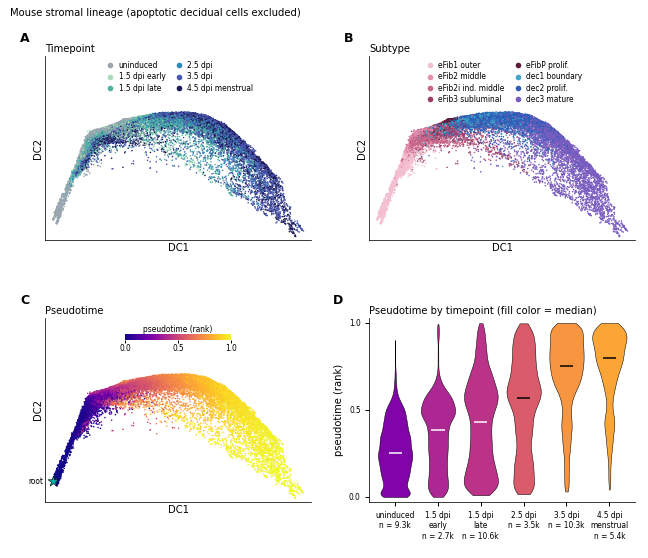

wrote S20A_mouse_diffusion_map_by_timepoint.svg


wrote S20B_mouse_diffusion_map_by_subtype.svg


wrote S20C_mouse_diffusion_map_by_pseudotime.svg


wrote S20D_mouse_pseudotime_by_timepoint.svg
{'n_nuclei': 42966, 'n_with_pseudotime': 41791, 'n_drawn_in_A_C': 41791, 'root': 'CCCTGATAGGTATTGA-1-uninduced_mck8b'}


In [10]:
mouse_outputs, mouse_counts = draw_mouse_supplement(cells["mouse"], roots["mouse"], OUT)
print(mouse_counts)

## Fig. S27 · human

wrote S27_human_pseudotime_composite.svg


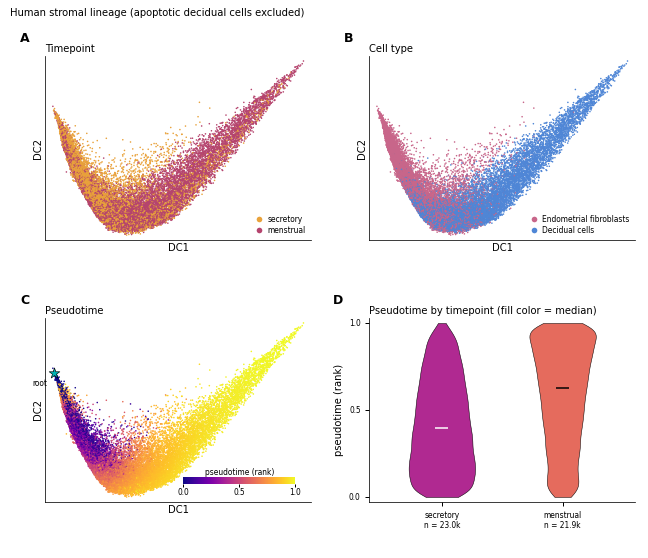

wrote S27A_human_diffusion_map_by_cycle_phase.svg


wrote S27B_human_diffusion_map_by_celltype.svg


wrote S27C_human_diffusion_map_by_pseudotime.svg


wrote S27D_human_pseudotime_by_timepoint.svg
{'n_nuclei': 46818, 'n_with_pseudotime': 44949, 'n_drawn_in_A_C': 44949, 'root': 'CGGGTCATCAGATTGC-1-secretory_mck6c'}


In [11]:
human_outputs, human_counts = draw_human_supplement(cells["human"], roots["human"], OUT)
print(human_counts)

## Provenance

Input objects (sha256, counts, root) and output files (sha256).

In [12]:
record = {
    "written": datetime.datetime.now().isoformat(timespec="seconds"),
    "notebook": "figures/S20_S27_pseudotime_trajectories.ipynb",
    "matplotlib": matplotlib.__version__,
    "font": font,
    "inputs": {"mouse": sources["mouse"] | mouse_counts, "human": sources["human"] | human_counts},
    "outputs": {path.name: sha256_of(path) for path in mouse_outputs + human_outputs},
}
provenance = OUT / "pseudotime_supplements_provenance.json"
provenance.write_text(json.dumps(record, indent=1) + "\n")
print(f"wrote {provenance.name}")

wrote pseudotime_supplements_provenance.json
